# ATRO – Billing Agent: Model Training, Factor Functions & Decision Layer

**Flow:** load preprocessed data → split → intent classifier → risk (fraud) model → RAG → Groq/Llama billing agent →
build labelled agent-output set → compute T, E, Hr, Cf, R → fit α…λ → tune thresholds → evaluate (baseline + ablation).

Inputs (from your preprocessing notebook): `billing_support_qa.csv`, `billing_amazon_reviews.csv`, `billing_invoice_summary.csv`
(plus `billing_transactions.csv` is not needed here).

**Decision rule:**  D = αT + βE + γHr + δ(1 − Cf) + λ(1 − R), with α+β+γ+δ+λ = 1  
(equivalent to αT + βE + γHr − δCf − λR plus the constant δ+λ, which keeps D inside [0,1]).

## 0. Setup

In [ ]:
!pip -q install sentence-transformers faiss-cpu groq scikit-learn transformers accelerate joblib

In [35]:
import os, re, json, time, random, math, hashlib, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = "/content"
OUT_DIR  = "/content/atro_billing_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Groq key: add GROQ_API_KEY under Colab "Secrets" (key icon on the left) ----
try:
    from google.colab import userdata
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except Exception:
    GROQ_API_KEY = os.environ.get("GROQ_API_KEY")

AGENT_MODEL = "openai/gpt-oss-20b"    # the billing agent
JUDGE_MODEL = "openai/gpt-oss-120b"  # used only to LABEL correctness (not part of ATRO at run time)
EMB_MODEL   = "sentence-transformers/all-MiniLM-L6-v2"
NLI_MODEL   = "cross-encoder/nli-deberta-v3-small"
TOP_K = 3

# How many evaluation queries to run through the agent (each = 1 agent call + 1 judge call for policy queries)
N_Q = dict(val_policy=20, test_policy=15, val_invoice=10, test_invoice=10)

# ---- ATRO hyper-parameters (documented in the report) ----
E_W = dict(S=0.25, Rel=0.35, Comp=0.25, F=0.15)            # evidence weights, sum = 1
R_W = dict(fin=0.30, sec=0.20, fraud=0.30, cust=0.20)      # risk weights, sum = 1
SOURCE_RELIABILITY = {"customer_support": 1.0, "invoice_db": 1.0, "amazon_review": 0.4}
SOURCE_FRESHNESS   = {"customer_support": 1.0, "amazon_review": 0.5}   # no timestamps in these sources
FRESH_TAU_DAYS = 730                                        # invoice evidence decays with age
INTENT_SEVERITY = {"REFUND": 0.9, "PAYMENT": 0.7, "BILLING_INFORMATION": 0.5,
                   "DISCOUNT_PROMOTION": 0.4, "BILLING_OTHER": 0.4, "INVOICE_RECEIPT": 0.2}
REQUIRED_FIELDS = {"REFUND": ["policy", "invoice"], "INVOICE_RECEIPT": ["invoice"], "PAYMENT": ["policy"],
                   "DISCOUNT_PROMOTION": ["policy"], "BILLING_INFORMATION": ["policy"], "BILLING_OTHER": ["policy"]}
INVOICE_INTENTS = {"REFUND", "INVOICE_RECEIPT", "PAYMENT"}  # intents that get an invoice context in the simulation
NLI_THRESHOLD = 0.5
R_MAX = 0.85                                                # hard rule: R above this -> always escalate

# Cost model for choosing thresholds (per query). Wrong answers that are auto-accepted are expensive.
UTIL = dict(accept_correct=1.0, accept_wrong=-5.0, verify=0.6, escalate=0.3)
print("Config loaded. Groq key found:", bool(GROQ_API_KEY))

Config loaded. Groq key found: True


## 1. Load data and split (freeze the test set before any modelling)

In [5]:
from sklearn.model_selection import train_test_split

need = ["billing_support_qa.csv", "billing_amazon_reviews.csv", "billing_invoice_summary.csv"]
if not all(os.path.exists(f"{DATA_DIR}/{f}") for f in need):
    from google.colab import files
    print("Upload the 3 CSVs created by the preprocessing notebook:", need)
    files.upload()

sup  = pd.read_csv(f"{DATA_DIR}/billing_support_qa.csv").dropna(subset=["query_text", "reference_response"]).reset_index(drop=True)
amz  = pd.read_csv(f"{DATA_DIR}/billing_amazon_reviews.csv").dropna(subset=["query_text"]).reset_index(drop=True)
inv  = pd.read_csv(f"{DATA_DIR}/billing_invoice_summary.csv", parse_dates=["InvoiceDate"])
print(sup.shape, amz.shape, inv.shape)

# Merge very rare intents so stratified splitting works
vc = sup["category"].value_counts()
rare = vc[vc < 15].index
sup["label"] = np.where(sup["category"].isin(rare), "BILLING_OTHER", sup["category"])
print(sup["label"].value_counts())

sup_train, tmp = train_test_split(sup, test_size=0.30, stratify=sup["label"], random_state=SEED)
sup_val, sup_test = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=SEED)
print("support split:", len(sup_train), len(sup_val), len(sup_test))

# Invoice split (random, by invoice)
inv = inv.dropna(subset=["TotalAmount"]).reset_index(drop=True)
inv_train, tmp = train_test_split(inv, test_size=0.30, random_state=SEED)
inv_val, inv_test = train_test_split(tmp, test_size=0.50, random_state=SEED)
print("invoice split:", len(inv_train), len(inv_val), len(inv_test))

# Small file for HAND-LABELLING real intents (your regex labels are weak labels!)
sup_test.sample(min(150, len(sup_test)), random_state=SEED)[["doc_id", "query_text", "label"]] \
    .assign(hand_label="").to_csv(f"{OUT_DIR}/intent_handlabel_template.csv", index=False)

(81, 6) (686, 6) (25898, 9)
label
DISCOUNT_PROMOTION    47
PAYMENT               18
BILLING_OTHER         16
Name: count, dtype: int64
support split: 56 12 13
invoice split: 18128 3885 3885


## 2. Intent classifier

Intents were produced by regex over *question + answer*. The classifier only sees the **question**, so it must learn the
real signal instead of memorising the regex. Report macro-F1 (classes are imbalanced), and re-score on the hand-labelled
file when you have it.

In [6]:
print("Original category distribution:")
print(sup["category"].value_counts())

print("\nMerged label distribution:")
print(sup["label"].value_counts())

print("\nSample questions and labels:")
display(
    sup[["query_text", "category", "label"]]
    .sample(min(15, len(sup)), random_state=42)
)

Original category distribution:
category
DISCOUNT_PROMOTION     47
PAYMENT                18
REFUND                  8
BILLING_INFORMATION     6
INVOICE_RECEIPT         2
Name: count, dtype: int64

Merged label distribution:
label
DISCOUNT_PROMOTION    47
PAYMENT               18
BILLING_OTHER         16
Name: count, dtype: int64

Sample questions and labels:


,query_text,category,label
30,Can I return an item without a receipt?,INVOICE_RECEIPT,BILLING_OTHER
0,My payment was declined. What should I do?,PAYMENT,PAYMENT
22,Can I order multiple items and pay separately?,PAYMENT,PAYMENT
31,How do I know if a coupon is valid?,DISCOUNT_PROMOTION,DISCOUNT_PROMOTION
18,Do you offer discounts for first-time buyers?,DISCOUNT_PROMOTION,DISCOUNT_PROMOTION
28,How do I request a refund?,REFUND,BILLING_OTHER
10,Can I pay in installments?,PAYMENT,PAYMENT
70,Can I combine VIP and standard gift cards for ...,DISCOUNT_PROMOTION,DISCOUNT_PROMOTION
4,Can I change my billing address?,BILLING_INFORMATION,BILLING_OTHER
12,Can I combine a gift card and discount code?,DISCOUNT_PROMOTION,DISCOUNT_PROMOTION


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, f1_score, accuracy_score

tfidf_clf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=3000, class_weight="balanced", C=5))
tfidf_clf.fit(sup_train["query_text"], sup_train["label"])

for name, d in [("val", sup_val), ("test", sup_test)]:
    p = tfidf_clf.predict(d["query_text"])
    print(f"[TF-IDF+LR] {name}: acc={accuracy_score(d['label'], p):.3f}  macro-F1={f1_score(d['label'], p, average='macro'):.3f}")
print(classification_report(sup_test["label"], tfidf_clf.predict(sup_test["query_text"]), zero_division=0))

[TF-IDF+LR] val: acc=1.000  macro-F1=1.000
[TF-IDF+LR] test: acc=0.846  macro-F1=0.792
                    precision    recall  f1-score   support

     BILLING_OTHER       1.00      1.00      1.00         3
DISCOUNT_PROMOTION       0.78      1.00      0.88         7
           PAYMENT       1.00      0.33      0.50         3

          accuracy                           0.85        13
         macro avg       0.93      0.78      0.79        13
      weighted avg       0.88      0.85      0.82        13



### 2b. Fine-tune DistilBERT (set `RUN_BERT=False` to skip; use a GPU runtime)

In [8]:
RUN_BERT = True
bert_ready = False
if RUN_BERT:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

    labels = sorted(sup_train["label"].unique()); l2i = {l: i for i, l in enumerate(labels)}
    tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

    class DS(torch.utils.data.Dataset):
        def __init__(self, df):
            self.enc = tok(df["query_text"].tolist(), truncation=True, padding=True, max_length=96)
            self.y = df["label"].map(l2i).tolist()
        def __len__(self): return len(self.y)
        def __getitem__(self, i):
            d = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
            d["labels"] = torch.tensor(self.y[i]); return d

    bert = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased", num_labels=len(labels),
        id2label={i: l for l, i in l2i.items()}, label2id=l2i)

    def compute_metrics(p):
        pr = p.predictions.argmax(-1)
        return {"macro_f1": f1_score(p.label_ids, pr, average="macro"), "acc": float((pr == p.label_ids).mean())}

    kw = dict(output_dir=f"{OUT_DIR}/bert_ckpt", num_train_epochs=4, per_device_train_batch_size=16,
              per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01, save_strategy="epoch",
              load_best_model_at_end=True, metric_for_best_model="macro_f1", report_to="none", seed=SEED)
    try:    args = TrainingArguments(eval_strategy="epoch", **kw)
    except TypeError: args = TrainingArguments(evaluation_strategy="epoch", **kw)

    trainer = Trainer(model=bert, args=args, train_dataset=DS(sup_train), eval_dataset=DS(sup_val),
                      compute_metrics=compute_metrics)
    trainer.train()
    print("TEST:", trainer.evaluate(DS(sup_test)))
    bert_ready = True

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1,Acc
No log,1.015585,4,0.233333,0.538462


TEST: {'eval_loss': 1.0155847072601318, 'eval_macro_f1': 0.2333333333333333, 'eval_acc': 0.5384615384615384}


In [10]:
# Choose the better intent model on VALIDATION macro-F1 (never on test)
def _bert_predict(texts):
    bert.eval(); out = []
    dev = next(bert.parameters()).device
    for i in range(0, len(texts), 64):
        enc = tok(list(texts[i:i+64]), truncation=True, padding=True, max_length=96, return_tensors="pt").to(dev)
        with torch.no_grad(): out += bert(**enc).logits.argmax(-1).cpu().tolist()
    return [labels[i] for i in out]

use_bert = False
if bert_ready:
    f_bert  = f1_score(sup_val["label"], _bert_predict(sup_val["query_text"].tolist()), average="macro")
    f_tfidf = f1_score(sup_val["label"], tfidf_clf.predict(sup_val["query_text"]), average="macro")
    use_bert = f_bert > f_tfidf
    print(f"val macro-F1  BERT={f_bert:.3f}  TF-IDF={f_tfidf:.3f}  -> using {'BERT' if use_bert else 'TF-IDF'}")

def predict_intent(texts):
    texts = list(texts)
    return _bert_predict(texts) if use_bert else list(tfidf_clf.predict(texts))

joblib.dump(tfidf_clf, f"{OUT_DIR}/intent_tfidf_lr.joblib")

val macro-F1  BERT=0.246  TF-IDF=1.000  -> using TF-IDF


['/content/atro_billing_outputs/intent_tfidf_lr.joblib']

## 3. Risk model (fraud / anomaly) on invoices

Online Retail has **no fraud labels**, so we use unsupervised anomaly detection (Isolation Forest) on invoice- and
customer-level behaviour, then map the anomaly score to [0,1] with the training-set empirical CDF.
Customer statistics are computed from the **training** invoices only.

In [11]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest

def add_basic(df):
    df = df.copy()
    df["abs_amt"]  = df["TotalAmount"].abs()
    df["is_cancel"] = (df["TransactionType"] == "Cancellation").astype(int)
    df["is_return"] = (df["TransactionType"] == "Return/Adjustment").astype(int)
    df["cust_missing"] = df["CustomerID"].isna().astype(int)
    return df

inv_train, inv_val, inv_test = map(add_basic, (inv_train, inv_val, inv_test))

# customer behaviour profile from TRAIN invoices only
cust = (inv_train.dropna(subset=["CustomerID"]).groupby("CustomerID")
        .agg(c_n=("InvoiceNo", "size"), c_cancel=("is_cancel", "mean"), c_return=("is_return", "mean"),
             c_mean=("abs_amt", "mean")).reset_index())
cust_idx = cust.set_index("CustomerID")
glob = cust[["c_n", "c_cancel", "c_return", "c_mean"]].median()

def customer_feats(df):
    c = df[["CustomerID"]].join(cust_idx, on="CustomerID")
    for col in ["c_n", "c_cancel", "c_return", "c_mean"]:
        c[col] = c[col].fillna(glob[col])
    return c[["c_n", "c_cancel", "c_return", "c_mean"]]

RISK_FEATS = ["log_amt", "log_lines", "log_products", "log_qty", "is_cancel", "is_return",
              "cust_missing", "c_cancel", "c_return", "log_c_n", "log_amt_ratio"]
def risk_matrix(df):
    c = customer_feats(df)
    X = pd.DataFrame(index=df.index)
    X["log_amt"]      = np.log1p(df["abs_amt"])
    X["log_lines"]    = np.log1p(df["LineCount"])
    X["log_products"] = np.log1p(df["UniqueProducts"])
    X["log_qty"]      = np.log1p(df["TotalQuantity"].abs())
    X["is_cancel"], X["is_return"], X["cust_missing"] = df["is_cancel"], df["is_return"], df["cust_missing"]
    X["c_cancel"], X["c_return"] = c["c_cancel"], c["c_return"]
    X["log_c_n"]      = np.log1p(c["c_n"])
    X["log_amt_ratio"] = np.log1p(df["abs_amt"] / (c["c_mean"] + 1))
    return X[RISK_FEATS].values

scaler = MinMaxScaler().fit(risk_matrix(inv_train))                 # normalise to 0-1 (train stats only)
iforest = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED, n_jobs=-1)
iforest.fit(scaler.transform(risk_matrix(inv_train)))

train_raw = np.sort(-iforest.decision_function(scaler.transform(risk_matrix(inv_train))))
def fraud_score(df):
    raw = -iforest.decision_function(scaler.transform(risk_matrix(df)))
    return np.searchsorted(train_raw, raw) / len(train_raw)         # empirical CDF -> [0,1]

for d in (inv_val, inv_test): d["fraud_r"] = fraud_score(d)

# constants for the other risk components
AMT_P99 = inv_train["abs_amt"].quantile(0.99)
country_share = inv_train["Country"].value_counts(normalize=True)
print("P99 amount:", round(AMT_P99, 2))
print("\nTop-10 most anomalous VALIDATION invoices (sanity check by eye):")
display(inv_val.sort_values("fraud_r", ascending=False)
        [["InvoiceNo", "CustomerID", "Country", "TransactionType", "TotalAmount", "fraud_r"]].head(10))
joblib.dump(dict(scaler=scaler, iforest=iforest, train_raw=train_raw, cust=cust, glob=glob,
                 AMT_P99=AMT_P99, country_share=country_share), f"{OUT_DIR}/risk_model.joblib")

P99 amount: 4527.29

Top-10 most anomalous VALIDATION invoices (sanity check by eye):


,InvoiceNo,CustomerID,Country,TransactionType,TotalAmount,fraud_r
576,537434,NaN,United Kingdom,Sale,8223.40,0.999779
482,537240,NaN,United Kingdom,Sale,7660.48,0.999559
21052,579508,NaN,United Kingdom,Sale,5805.01,0.998842
20537,578347,NaN,United Kingdom,Sale,5526.53,0.998676
22395,C540117,NaN,United Kingdom,Cancellation,-16888.02,0.998566
19854,577078,NaN,United Kingdom,Sale,5217.83,0.998124
25893,C581484,16446.0,United Kingdom,Cancellation,-168469.60,0.998069
24168,C559917,NaN,United Kingdom,Cancellation,-6497.47,0.997573
24002,C558036,NaN,United Kingdom,Cancellation,-5791.18,0.997518
25406,C574897,NaN,United Kingdom,Cancellation,-5877.18,0.997518


['/content/atro_billing_outputs/risk_model.joblib']

## 4. RAG index (train-split evidence only – no leakage of test answers)

In [15]:
!pip install -q faiss-cpu sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 8.1 MB/s eta 0:00:00


In [16]:
import faiss
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer(EMB_MODEL)

docs = pd.concat([
    pd.DataFrame({"text": sup_train["query_text"] + " -> " + sup_train["reference_response"],
                  "source": "customer_support", "label": sup_train["label"].values}),
    pd.DataFrame({"text": amz["query_text"].str[:500], "source": "amazon_review", "label": amz["category"].values}),
], ignore_index=True)

doc_emb = emb_model.encode(docs["text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True).astype("float32")
index = faiss.IndexFlatIP(doc_emb.shape[1]); index.add(doc_emb)

def retrieve(query, k=TOP_K):
    q = emb_model.encode([query], normalize_embeddings=True).astype("float32")
    s, i = index.search(q, k)
    return [dict(text=docs.at[j, "text"], source=docs.at[j, "source"], label=docs.at[j, "label"], score=float(sc))
            for sc, j in zip(s[0], i[0])]

# retrieval quality: does any top-3 *support* doc share the query's intent label?
hits = []
for _, r in sup_val.sample(min(300, len(sup_val)), random_state=SEED).iterrows():
    hits.append(any(d["label"] == r["label"] for d in retrieve(r["query_text"], 5) if d["source"] == "customer_support"))
print(f"Retrieval intent-hit@5 on val: {np.mean(hits):.3f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Retrieval intent-hit@5 on val: 1.000


In [21]:
%pip install -q groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.2 MB/s eta 0:00:00


In [24]:
import groq
print("Groq installed successfully!")

Groq installed successfully!


## 5. Billing agent (Llama via Groq + RAG + invoice-lookup tool)

In [27]:
from google.colab import userdata

GROQ_API_KEY = userdata.get("GROQ_API_KEY")

print("Groq API key found:", bool(GROQ_API_KEY))

Groq API key found: True


In [32]:
from google.colab import userdata

GROQ_API_KEY = userdata.get("GROQ_API_KEY")

print("API key found:", bool(GROQ_API_KEY))

if GROQ_API_KEY:
    print("API key length:", len(GROQ_API_KEY))

API key found: True
API key length: 56


In [46]:
from groq import Groq

# ============================================================
# 1. INITIALIZE GROQ CLIENT
# ============================================================

if GROQ_API_KEY:
    client = Groq(api_key=GROQ_API_KEY)
    print("Groq API key found. Client initialized.")
else:
    raise ValueError(
        "GROQ_API_KEY is missing. "
        "Please configure it in Google Colab Secrets."
    )


# ============================================================
# 2. RESPONSE CACHE
# ============================================================

CACHE_PATH = f"{OUT_DIR}/llm_cache.json"

os.makedirs(OUT_DIR, exist_ok=True)

if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "r", encoding="utf-8") as f:
        cache = json.load(f)
else:
    cache = {}


def save_cache():
    """Save successful LLM responses."""
    with open(CACHE_PATH, "w", encoding="utf-8") as f:
        json.dump(cache, f, ensure_ascii=False, indent=2)


# ============================================================
# 3. GROQ LLM FUNCTION
# ============================================================

def llm(model, system, user, max_tokens=250):

    key = hashlib.md5(
        (model + "||" + system + "||" + user).encode()
    ).hexdigest()

    if key in cache:
        return cache[key]

    for attempt in range(4):
        try:
            response = client.chat.completions.create(
                model=model,
                temperature=0.0,
                max_tokens=max_tokens,
                reasoning_effort="low",
                messages=[
                    {"role": "system", "content": system},
                    {"role": "user", "content": user}
                ]
            )

            answer = response.choices[0].message.content

            if not answer:
                raise ValueError("Groq returned an empty response.")

            answer = answer.strip()

            cache[key] = answer
            save_cache()

            return answer

        except Exception as e:
            print(
                f"Groq attempt {attempt + 1} failed: "
                f"{type(e).__name__}: {e}"
            )

            # Retry only temporary failures
            if attempt < 3:
                time.sleep(2 ** attempt)

    raise RuntimeError(
        "Groq API failed after 4 attempts. "
        "Check the error messages above."
    )


# ============================================================
# 4. FORMAT INVOICE INFORMATION
# ============================================================

def invoice_text(row):

    cid = (
        "unknown"
        if pd.isna(row["CustomerID"])
        else int(row["CustomerID"])
    )

    return (
        f"Invoice {row['InvoiceNo']}: customer {cid}, "
        f"country {row['Country']}, "
        f"date {pd.Timestamp(row['InvoiceDate']).date()}, "
        f"{int(row['LineCount'])} line items, "
        f"total amount {row['TotalAmount']:.2f}, "
        f"type {row['TransactionType']}."
    )


# ============================================================
# 5. BILLING AGENT SYSTEM PROMPT
# ============================================================

AGENT_SYS = (
    "You are a billing support agent for a fashion e-commerce store. "
    "Answer ONLY from the evidence given. "
    "Treat customer reviews as customer experiences, not official policies. "
    "If the evidence is insufficient, say you cannot confirm and "
    "recommend review by a human agent. "
    "Never invent invoice details or claim a refund is approved "
    "unless the evidence explicitly confirms it. "
    "Reply in at most 3 short sentences. "
    "Quote amounts exactly as in the invoice record."
)


# ============================================================
# 6. BILLING AGENT WITH RAG
# ============================================================

def agent_answer(query, invoice=None):

    # Retrieve relevant evidence from FAISS
    docs_ = retrieve(query)

    ev = "\n".join(
        f"[{i + 1}] ({d['source']}) "
        f"Category: {d['label']} "
        f"Evidence: {d['text'][:400]}"
        for i, d in enumerate(docs_)
    )

    # Add invoice evidence if supplied
    if invoice is not None:
        ev += "\n[INVOICE RECORD] " + invoice_text(invoice)

    user_prompt = (
        f"Evidence:\n{ev}\n\n"
        f"Customer question: {query}"
    )

    # Generate the actual response through Groq
    answer = llm(
        AGENT_MODEL,
        AGENT_SYS,
        user_prompt,
        max_tokens=250
    )

    return {
        "answer": answer,
        "docs": docs_,
        "invoice": invoice
    }


# ============================================================
# 7. SMOKE TEST
# ============================================================

print("\nTesting Billing Agent...\n")

result = agent_answer(
    "How do I get a refund for a damaged dress?"
)

print("Customer question:")
print("How do I get a refund for a damaged dress?")

print("\nBilling Agent response:")
print(result["answer"])

print("\nRetrieved documents:", len(result["docs"]))

print("\nGroq integration test completed.")

Groq API key found. Client initialized.

Testing Billing Agent...

Customer question:
How do I get a refund for a damaged dress?

Billing Agent response:
I’m sorry, but I don’t have any information on how to request a refund for a damaged dress. Please contact a human agent for assistance.

Retrieved documents: 3

Groq integration test completed.


## 6. ATRO factor functions

| Factor | Function |
|---|---|
| **T** | per-intent smoothed accuracy `(c+1)/(n+2)`, updated *prequentially* (only past outcomes) |
| **E** | `w1·S + w2·Rel + w3·Comp + w4·F` |
| **Hr** | supported claims / total claims (NLI entailment ≥ 0.5) |
| **Cf** | contradicted claims / total claims, also 1 if a quoted amount disagrees with the invoice DB |
| **R** | `w1·Fin + w2·Sec + w3·Fraud + w4·CustImpact` |

In [37]:
from sentence_transformers import CrossEncoder
from scipy.special import softmax
nli = CrossEncoder(NLI_MODEL)           # output order: [contradiction, entailment, neutral]
REF_DATE = inv["InvoiceDate"].max()

# ---------- Trust ----------
class TrustTracker:
    def __init__(self): self.c, self.n = {}, {}
    def get(self, intent): return (self.c.get(intent, 0) + 1) / (self.n.get(intent, 0) + 2)
    def update(self, intent, ok):
        self.n[intent] = self.n.get(intent, 0) + 1; self.c[intent] = self.c.get(intent, 0) + int(ok)

# ---------- Evidence quality ----------
def evidence_quality(docs_, invoice, intent, exact_lookup=False, w=E_W):
    srcs = [d["source"] for d in docs_] + (["invoice_db"] if invoice is not None else [])
    S = float(np.mean([SOURCE_RELIABILITY[s] for s in srcs])) if srcs else 0.0
    Rel = 1.0 if exact_lookup else float(np.mean([min(max(d["score"], 0), 1) for d in docs_]))
    have = {"policy": any(d["source"] == "customer_support" and d["score"] >= 0.35 for d in docs_),
            "invoice": invoice is not None}
    req = REQUIRED_FIELDS.get(intent, ["policy"])
    Comp = float(np.mean([have[f] for f in req]))
    fr = [SOURCE_FRESHNESS[d["source"]] for d in docs_]
    if invoice is not None:
        age = (REF_DATE - pd.Timestamp(invoice["InvoiceDate"])).days
        fr.append(math.exp(-max(age, 0) / FRESH_TAU_DAYS))
    F = float(np.mean(fr)) if fr else 0.0
    E = w["S"] * S + w["Rel"] * Rel + w["Comp"] * Comp + w["F"] * F
    return dict(E=E, S=S, Rel=Rel, Comp=Comp, F=F)

# ---------- Hallucination reliability & conflict ----------
def split_claims(text):
    parts = re.split(r"(?<=[.!?])\s+", text.strip())
    return [p for p in parts if len(p.split()) >= 4]

AMOUNT_RE = re.compile(r"[£$€₹]\s?\d[\d,]*(?:\.\d{1,2})?|\d[\d,]*\.\d{1,2}")
def numeric_conflict(answer, invoice):
    if invoice is None: return 0.0
    amts = [float(a.replace(",", "").lstrip("£$€₹ ")) for a in AMOUNT_RE.findall(answer)]
    if not amts: return 0.0
    true = abs(float(invoice["TotalAmount"]))
    return 0.0 if any(abs(abs(a) - true) <= 0.01 for a in amts) else 1.0

def hallucination_and_conflict(answer, docs_, invoice):
    claims = split_claims(answer)
    ev = [d["text"][:500] for d in docs_] + ([invoice_text(invoice)] if invoice is not None else [])
    if not claims or not ev:
        return dict(Hr=0.0, Cf=max(numeric_conflict(answer, invoice), 0.0), n_claims=len(claims))
    pairs = [(e, c) for c in claims for e in ev]
    out = np.array(nli.predict(pairs, batch_size=32))
    if not (out.min() >= 0 and np.allclose(out.sum(1), 1, atol=1e-3)): out = softmax(out, axis=1)
    out = out.reshape(len(claims), len(ev), 3)
    ent, con = out[:, :, 1].max(1), out[:, :, 0].max(1)
    supported = ent >= NLI_THRESHOLD
    contradicted = (~supported) & (con >= NLI_THRESHOLD)
    return dict(Hr=float(supported.mean()),
                Cf=max(float(contradicted.mean()), numeric_conflict(answer, invoice)),
                n_claims=len(claims))

# ---------- Risk ----------
def risk_score(invoice, intent, w=R_W):
    if invoice is None:
        fin = sec = fraud = 0.0
    else:
        amt = abs(float(invoice["TotalAmount"]))
        fin = min(1.0, math.log1p(amt) / math.log1p(AMT_P99))
        rare = 1.0 if country_share.get(invoice["Country"], 0.0) < 0.01 else 0.0
        sec = 0.6 * float(pd.isna(invoice["CustomerID"])) + 0.4 * rare
        fraud = float(invoice["fraud_r"])
    cust_r = INTENT_SEVERITY.get(intent, 0.4)
    R = w["fin"] * fin + w["sec"] * sec + w["fraud"] * fraud + w["cust"] * cust_r
    return dict(R=R, Fin=fin, Sec=sec, Fraud=fraud, Cust=cust_r)
print("factor functions ready")

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

...

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

factor functions ready


## 7. Build the labelled agent-output set

Two query types, both from **held-out** splits:

* **policy** – real support questions. Refund/payment/receipt questions are paired with a *sampled held-out invoice* as context
  (a simulation, so that the risk model has something to score – state this in your report). Correctness labelled by an LLM judge vs. the reference answer.
* **invoice** – "what is the total on invoice X?" answered from the DB. Correctness is a deterministic number check.

**Fault injection** creates the failures ATRO has to catch: 25 % of policy answers are swapped with an answer to an unrelated question;
30 % of invoice answers get a wrong amount.

In [38]:
rng = random.Random(SEED)
INV_TEMPLATES = ["What is the total amount on invoice {n}?", "Can you confirm how much I was billed for invoice {n}?",
                 "I need the total charge for invoice {n}, please.", "How much does invoice {n} come to?"]

def make_records(split, sup_df, inv_df, n_policy, n_invoice):
    recs = []
    qs = sup_df.sample(min(n_policy, len(sup_df)), random_state=SEED)
    intents = predict_intent(qs["query_text"].tolist())
    for (_, r), it in zip(qs.iterrows(), intents):
        invoice = inv_df.sample(1, random_state=rng.randint(0, 10**6)).iloc[0] if it in INVOICE_INTENTS else None
        recs.append(dict(split=split, kind="policy", query=r["query_text"], reference=r["reference_response"],
                         gold_intent=r["label"], intent=it, invoice=invoice))
    pool = inv_df[(inv_df["abs_amt"] > 0)]
    for _, row in pool.sample(min(n_invoice, len(pool)), random_state=SEED).iterrows():
        recs.append(dict(split=split, kind="invoice", query=rng.choice(INV_TEMPLATES).format(n=row["InvoiceNo"]),
                         reference=None, gold_intent="INVOICE_RECEIPT", intent="INVOICE_RECEIPT", invoice=row))
    return recs

records = (make_records("val", sup_val, inv_val, N_Q["val_policy"], N_Q["val_invoice"]) +
           make_records("test", sup_test, inv_test, N_Q["test_policy"], N_Q["test_invoice"]))
print(len(records), "records")

45 records


In [39]:
from tqdm.auto import tqdm
# 1) run the agent
for r in tqdm(records, desc="agent"):
    out = agent_answer(r["query"], r["invoice"])
    r["docs"], r["answer"], r["corrupted"] = out["docs"], out["answer"], 0
save_cache()

# 2) fault injection
policy_recs = [r for r in records if r["kind"] == "policy"]
for r in policy_recs:
    if rng.random() < 0.25:
        other = rng.choice([o for o in policy_recs if o["gold_intent"] != r["gold_intent"]])
        r["answer"], r["corrupted"] = other["answer"], 1
for r in records:
    if r["kind"] == "invoice" and rng.random() < 0.30:
        true = abs(float(r["invoice"]["TotalAmount"]))
        wrong = round(true * rng.choice([0.5, 1.3, 1.8, 2.5]) + rng.choice([0, 3.2, 10]), 2)
        r["answer"], r["corrupted"] = f"The total amount on invoice {r['invoice']['InvoiceNo']} is £{wrong:.2f}.", 1
print("corrupted:", sum(r["corrupted"] for r in records), "/", len(records))

agent:   0%|          | 0/45 [00:00<?, ?it/s]

corrupted: 12 / 45


In [47]:
# 3) Correctness labels using the Judge Model

JUDGE_SYS = (
    "You are a strict grader. Given a customer question, a reference "
    "answer and a candidate answer, reply with exactly CORRECT if the "
    "candidate is consistent with the reference and addresses the question, "
    "otherwise reply with INCORRECT."
)

def judge(q, ref, cand):
    out = llm(
        JUDGE_MODEL,
        JUDGE_SYS,
        f"Question: {q}\nReference: {ref}\nCandidate: {cand}",
        max_tokens=300
    )

    out = out.strip().upper()

    if out.startswith("INCORRECT"):
        return 0
    elif out.startswith("CORRECT"):
        return 1
    else:
        raise ValueError(f"Unexpected judge response: {out!r}")


# Label all records
for r in tqdm(records, desc="labelling"):
    if r["kind"] == "invoice":
        r["correct"] = int(
            numeric_conflict(r["answer"], r["invoice"]) == 0
            and AMOUNT_RE.search(r["answer"]) is not None
        )
    else:
        r["correct"] = judge(
            r["query"],
            r["reference"],
            r["answer"]
        )

save_cache()

# Display evaluation summary
lab = pd.DataFrame([
    {
        k: r[k]
        for k in ["split", "kind", "intent", "corrupted", "correct"]
    }
    for r in records
])

print(lab.groupby(["split", "kind"])["correct"].agg(["mean", "size"]))

print("\nSPOT-CHECK approximately 30 judge labels manually:")
display(pd.DataFrame([
    {k: r[k] for k in ["query", "answer", "correct"]}
    for r in policy_recs[:30]
]))

labelling:   0%|          | 0/45 [00:00<?, ?it/s]

                   mean  size
split kind                   
test  invoice  0.700000    10
      policy   0.538462    13
val   invoice  0.600000    10
      policy   0.500000    12

SPOT-CHECK approximately 30 judge labels manually:


,query,answer,correct
0,How do I know if a promo code is valid?,Check the coupon’s expiration date and terms o...,1
1,Can I get a refund if I'm not satisfied with m...,"Yes, payment methods can be saved securely in ...",0
2,How do I know if my payment was successful?,"I’m sorry, I don’t have information on whether...",0
3,How do I apply multiple promo codes?,"Yes, payment methods can be saved securely in ...",0
4,What payment methods do you accept?,We accept multiple payment methods and you can...,0
5,Can I use multiple promo codes on one order?,"No, you can only apply one promo code per orde...",1
6,Can I split VIP payments between gift cards an...,"Yes, you can split VIP payments between gift c...",1
7,Can I get a refund if I received the wrong item?,"I’m sorry, but I don’t have evidence that a re...",0
8,Do you offer student discounts for online purc...,"Yes, we offer student discounts. \nVerify you...",1
9,My payment was declined. What should I do?,It looks like your payment was declined. \nYo...,0


In [42]:
# Diagnose the Judge Model response

print("Judge model:", JUDGE_MODEL)

try:
    response = client.chat.completions.create(
        model=JUDGE_MODEL,
        messages=[
            {
                "role": "system",
                "content": "You are a grader. Reply with one word only."
            },
            {
                "role": "user",
                "content": "Reply with CORRECT."
            }
        ],
        temperature=0,
        max_tokens=50
    )

    print("Model returned:", response.model)
    print("Finish reason:", response.choices[0].finish_reason)
    print("Response:", repr(response.choices[0].message.content))
    print("Usage:", response.usage)

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))

Judge model: openai/gpt-oss-120b
Model returned: openai/gpt-oss-120b
Finish reason: length
Response: ''
Usage: CompletionUsage(completion_tokens=50, prompt_tokens=90, total_tokens=140, completion_time=0.105107763, completion_tokens_details=CompletionTokensDetails(reasoning_tokens=48), prompt_time=0.003772066, prompt_tokens_details=None, queue_time=0.174730033, total_time=0.108879829)


In [43]:
response = client.chat.completions.create(
    model=JUDGE_MODEL,
    messages=[
        {
            "role": "system",
            "content": "Classify the answer. Output exactly CORRECT or INCORRECT."
        },
        {
            "role": "user",
            "content": (
                "Question: Is 2 greater than 1?\n"
                "Reference: Yes, 2 is greater than 1.\n"
                "Candidate: Yes, 2 is greater than 1.\n"
                "Classification:"
            )
        }
    ],
    temperature=0,
    max_tokens=300
)

print("Finish reason:", response.choices[0].finish_reason)
print("Judge response:", repr(response.choices[0].message.content))

Finish reason: stop
Judge response: 'CORRECT'


## 8. Compute the five ATRO factors for every record

In [48]:
rows = []
order = [r for r in records if r["split"] == "val"]; rng.shuffle(order)
order_t = [r for r in records if r["split"] == "test"]; rng.shuffle(order_t)
tracker = TrustTracker()
for r in tqdm(order + order_t, desc="factors"):          # prequential: T uses only PAST labels
    T = tracker.get(r["intent"])
    e = evidence_quality(r["docs"], r["invoice"], r["intent"], exact_lookup=(r["kind"] == "invoice"))
    h = hallucination_and_conflict(r["answer"], r["docs"], r["invoice"])
    k = risk_score(r["invoice"], r["intent"])
    rows.append(dict(split=r["split"], kind=r["kind"], intent=r["intent"], corrupted=r["corrupted"],
                     correct=r["correct"], T=T, E=e["E"], Hr=h["Hr"], Cf=h["Cf"], R=k["R"],
                     S=e["S"], Rel=e["Rel"], Comp=e["Comp"], F=e["F"], Fin=k["Fin"], Sec=k["Sec"],
                     Fraud=k["Fraud"], Cust=k["Cust"]))
    tracker.update(r["intent"], r["correct"])
feat_df = pd.DataFrame(rows)
feat_df.to_csv(f"{OUT_DIR}/atro_billing_features.csv", index=False)
val_df, test_df = feat_df[feat_df.split == "val"].copy(), feat_df[feat_df.split == "test"].copy()
print(len(val_df), len(test_df))
display(feat_df.groupby("correct")[["T", "E", "Hr", "Cf", "R"]].mean().round(3))

factors:   0%|          | 0/45 [00:00<?, ?it/s]

22 23


,T,E,Hr,Cf,R
correct,,,,,
0,0.507,0.837,0.123,0.596,0.276
1,0.605,0.893,0.910,0.000,0.233


## 9. Fit α, β, γ, δ, λ (validation set)

Logistic regression of `P(correct)` on the oriented features `[T, E, Hr, 1−Cf, 1−R]` with **non-negative weights**
(so each factor can only push confidence in its intended direction). The normalised weights become α…λ.

In [49]:
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score

ORIENT = ["T", "E", "Hr", "inv_Cf", "inv_R"]
def oriented(df):
    X = df[["T", "E", "Hr"]].copy(); X["inv_Cf"] = 1 - df["Cf"]; X["inv_R"] = 1 - df["R"]
    return X[ORIENT].values

def fit_constrained_lr(X, y, l2=1e-2):
    def loss(p):
        w, b = p[:-1], p[-1]; z = X @ w + b
        return np.mean(np.logaddexp(0, z) - y * z) + l2 * np.sum(w ** 2)
    p0 = np.r_[np.ones(X.shape[1]), -X.shape[1] / 2]
    res = minimize(loss, p0, method="L-BFGS-B", bounds=[(0, 20)] * X.shape[1] + [(-30, 30)])
    return res.x[:-1], res.x[-1]

Xv, yv = oriented(val_df), val_df["correct"].values
w_raw, b = fit_constrained_lr(Xv, yv)
w_norm = w_raw / w_raw.sum()
alpha, beta, gamma, delta, lam = w_norm
print(f"alpha(T)={alpha:.3f} beta(E)={beta:.3f} gamma(Hr)={gamma:.3f} delta(Cf)={delta:.3f} lambda(R)={lam:.3f}")

def D_score(df): return oriented(df) @ w_norm
def p_correct(df): return 1 / (1 + np.exp(-(oriented(df) @ w_raw + b)))
val_df["D"], test_df["D"] = D_score(val_df), D_score(test_df)
val_df["p"], test_df["p"] = p_correct(val_df), p_correct(test_df)
print(f"AUROC of D   val={roc_auc_score(yv, val_df['D']):.3f}   test={roc_auc_score(test_df['correct'], test_df['D']):.3f}")

alpha(T)=0.119 beta(E)=0.091 gamma(Hr)=0.394 delta(Cf)=0.246 lambda(R)=0.150
AUROC of D   val=0.983   test=0.897


## 10. Choose thresholds τ_a, τ_v on validation

Pick the pair maximising expected utility with the cost model in `UTIL` (wrong auto-accept is expensive).
**Hard rule:** if `R > R_MAX` the answer is always escalated.

In [50]:
def decide(D, R, tau_v, tau_a, r_max=R_MAX):
    d = np.where(D >= tau_a, "ACCEPT", np.where(D >= tau_v, "VERIFY", "ESCALATE"))
    return np.where(R > r_max, "ESCALATE", d)

def utility(decisions, correct):
    u = np.where(decisions == "ACCEPT", np.where(correct == 1, UTIL["accept_correct"], UTIL["accept_wrong"]),
        np.where(decisions == "VERIFY", UTIL["verify"], UTIL["escalate"]))
    return u.mean()

grid = np.unique(np.quantile(val_df["D"], np.linspace(0.02, 0.98, 60)))
best = (-1e9, None, None)
for tv in grid:
    for ta in grid[grid > tv]:
        u = utility(decide(val_df["D"].values, val_df["R"].values, tv, ta), val_df["correct"].values)
        if u > best[0]: best = (u, tv, ta)
_, TAU_V, TAU_A = best
print(f"tau_v={TAU_V:.3f}  tau_a={TAU_A:.3f}  val utility={best[0]:.3f}")

tau_v=0.197  tau_a=0.792  val utility=0.786


## 11. Evaluation on the held-out test set

In [51]:
def summarize(name, dec, df):
    acc = dec == "ACCEPT"
    return dict(system=name,
                accept_rate=acc.mean(), verify_rate=(dec == "VERIFY").mean(), escalate_rate=(dec == "ESCALATE").mean(),
                accuracy_of_accepted=df["correct"].values[acc].mean() if acc.any() else np.nan,
                wrong_accepted=int((df["correct"].values[acc] == 0).sum()),
                utility=utility(dec, df["correct"].values))

N_ = len(test_df)
atro_dec   = decide(test_df["D"].values, test_df["R"].values, TAU_V, TAU_A)
always_dec = np.array(["ACCEPT"] * N_)
static_dec = np.where(test_df["intent"].values == "REFUND", "ESCALATE", "ACCEPT")   # fixed-rule baseline
trust_only = decide(test_df["T"].values, np.zeros(N_), 0.0, np.quantile(val_df["T"], 0.5))  # T-only gate
res = pd.DataFrame([summarize("Always accept", always_dec, test_df),
                    summarize("Static rule (escalate refunds)", static_dec, test_df),
                    summarize("ATRO (T,E,Hr,Cf,R)", atro_dec, test_df)]).round(3)
display(res)
print("Test AUROC of D:", round(roc_auc_score(test_df["correct"], test_df["D"]), 3))

def ece(p, y, bins=8):
    edges = np.linspace(0, 1, bins + 1); e = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p <= hi if hi == 1 else p < hi)
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e
print("Calibration error (ECE) of P(correct):", round(ece(test_df["p"].values, test_df["correct"].values), 3))

,system,accept_rate,verify_rate,escalate_rate,accuracy_of_accepted,wrong_accepted,utility
0,Always accept,1.000,0.000,0.0,0.609,9,-1.348
1,Static rule (escalate refunds),1.000,0.000,0.0,0.609,9,-1.348
2,"ATRO (T,E,Hr,Cf,R)",0.565,0.435,0.0,0.923,1,0.565


Test AUROC of D: 0.897
Calibration error (ECE) of P(correct): 0.141


,test AUROC
T,0.433
E,0.706
Hr,0.933
1-Cf,0.889
1-R,0.472
T+E,0.556
T+E+Hr,0.897
T+E+Hr+Cf,0.897
ALL (ATRO),0.897


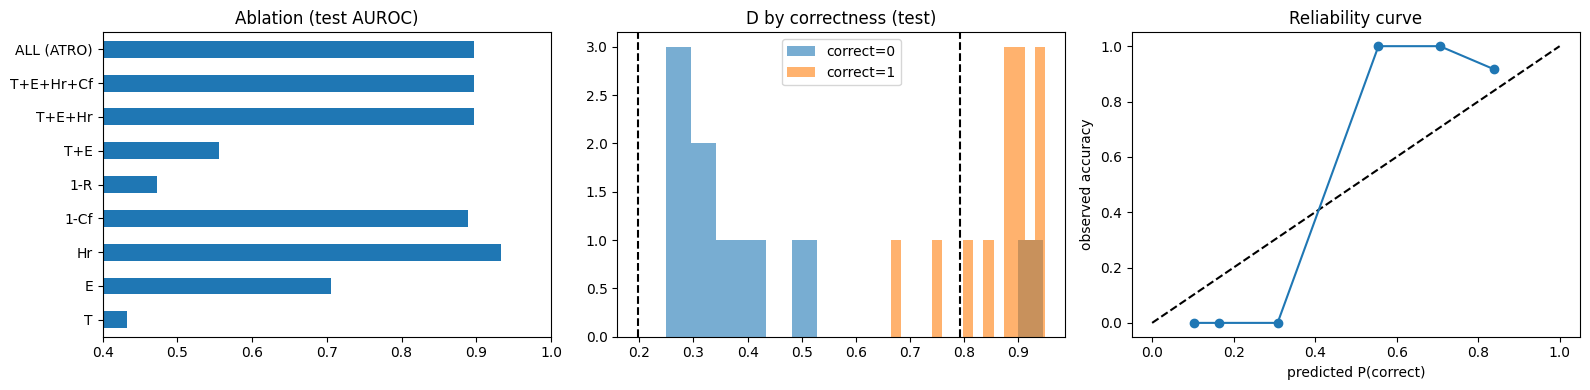

In [52]:
# Ablation: does each factor earn its place?  (fit on val, AUROC on test)
subsets = {"T": ["T"], "E": ["E"], "Hr": ["Hr"], "1-Cf": ["inv_Cf"], "1-R": ["inv_R"],
           "T+E": ["T", "E"], "T+E+Hr": ["T", "E", "Hr"], "T+E+Hr+Cf": ["T", "E", "Hr", "inv_Cf"],
           "ALL (ATRO)": ORIENT}
def odf(df):
    X = pd.DataFrame(oriented(df), columns=ORIENT, index=df.index); return X
Xv_df, Xt_df = odf(val_df), odf(test_df)
abl = {}
for name, cols in subsets.items():
    m = LogisticRegression(C=10, max_iter=2000).fit(Xv_df[cols], val_df["correct"])
    abl[name] = roc_auc_score(test_df["correct"], m.predict_proba(Xt_df[cols])[:, 1])
abl = pd.Series(abl).round(3); display(abl.to_frame("test AUROC"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
abl.plot.barh(ax=ax[0]); ax[0].set_title("Ablation (test AUROC)"); ax[0].set_xlim(0.4, 1)
for c, g in test_df.groupby("correct"): ax[1].hist(g["D"], bins=15, alpha=.6, label=f"correct={c}")
ax[1].axvline(TAU_V, ls="--", c="k"); ax[1].axvline(TAU_A, ls="--", c="k"); ax[1].legend(); ax[1].set_title("D by correctness (test)")
bins = pd.cut(test_df["p"], np.linspace(0, 1, 9)); cal = test_df.groupby(bins)[["p", "correct"]].mean().dropna()
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].plot(cal["p"], cal["correct"], "o-"); ax[2].set_title("Reliability curve")
ax[2].set_xlabel("predicted P(correct)"); ax[2].set_ylabel("observed accuracy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/atro_billing_results.png", dpi=150); plt.show()

## 12. Save everything

In [53]:
cfg = dict(weights=dict(alpha_T=alpha, beta_E=beta, gamma_Hr=gamma, delta_Cf=delta, lambda_R=lam),
           logistic_raw=dict(w=w_raw.tolist(), b=float(b)), tau_accept=float(TAU_A), tau_verify=float(TAU_V), R_MAX=R_MAX,
           E_weights=E_W, R_weights=R_W, util=UTIL, nli_threshold=NLI_THRESHOLD,
           intent_model="distilbert" if use_bert else "tfidf_lr")
json.dump(cfg, open(f"{OUT_DIR}/atro_billing_config.json", "w"), indent=2)
res.to_csv(f"{OUT_DIR}/atro_billing_results_table.csv", index=False)
abl.to_csv(f"{OUT_DIR}/atro_billing_ablation.csv")
save_cache()
print(json.dumps(cfg["weights"], indent=2)); print("tau_a / tau_v:", TAU_A, TAU_V)
import shutil; shutil.make_archive("/content/atro_billing_outputs", "zip", OUT_DIR)
from google.colab import files; files.download("/content/atro_billing_outputs.zip")

{
  "alpha_T": 0.11895316876039545,
  "beta_E": 0.09085501287852854,
  "gamma_Hr": 0.3940397350080439,
  "delta_Cf": 0.2461933099783706,
  "lambda_R": 0.14995877337466146
}
tau_a / tau_v: 0.7918571427708645 0.19699514078600727


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>